In [ ]:
import pandas as pd
import numpy as np

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
data = pd.read_csv('/content/Cleaned_data_readable.csv')

In [ ]:
!pip install category_encoders

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import cross_val_score, KFold
from category_encoders import TargetEncoder
import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.base import clone

In [ ]:
data = data[~data['Screen_Size'].isna()]
x = data.drop(columns=('Price'))
y = data['Price']
y = np.log(y)

In [ ]:
x['Is_Laptop'] = x['Type'].map({
    'Computer': 0,
    'Laptop': 1
})

x.drop(columns=['Type'], inplace=True)

x['RAM_GB'] = np.log2(x['RAM_GB'])

x.drop(columns=['Processor_Tier'], inplace=True)
categorical_col = ['Brand', 'Storage_Type', 'Processor']
numerical_col = ['RAM_GB', 'ROM_GB', 'Screen_Size', 'Warranty_Days']

processor =ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_col),
        ('num', StandardScaler(), numerical_col),
    ],
    remainder='passthrough'
)

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

# Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV

In [ ]:
lr = LinearRegression()

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', lr)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

Mean R²: 0.4907644996413055


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
lr = LinearRegression(fit_intercept= True, positive=True)

param_grid = {
    'model__fit_intercept': [True, False],
    'model__positive': [True, False]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.4910531486382005
Best Parameters: {'model__fit_intercept': True, 'model__positive': False}


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))

print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13489.635963304325
R2_Score 0.4337372843215106


Without exp (Log Scale)
MAE: 0.46576167364296894
R2_Score: 0.46169124975686515


# Ridge

In [ ]:
from sklearn.linear_model import Ridge

In [ ]:
model = Ridge(alpha=0.1)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

Mean R²: 0.49079533222898364


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12416.865144169835
R2_Score 0.4022992662438055


Without exp (Log Scale)
MAE: 0.4367091016115589
R2_Score: 0.48901533339828196


In [ ]:
param_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'model__fit_intercept': [True, False],
    'model__solver': [
        'auto', 'svd', 'cholesky',
        'lsqr', 'sag', 'saga'
    ]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1,
    error_score='raise'
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.4914986732528523
Best Parameters: {'model__alpha': 1, 'model__fit_intercept': True, 'model__solver': 'svd'}


In [ ]:
model = Ridge(alpha=1, fit_intercept=True, solver='svd')

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

Mean R²: 0.4914986732528523


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13528.209431993993
R2_Score 0.42786712122073955


Without exp (Log Scale)
MAE: 0.46564883762020604
R2_Score: 0.46081511492878324


# Lasso regression

In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
model = Lasso(alpha=1.0, max_iter=10000)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: -0.00647006484652417


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 18813.30758368794
R2_Score -0.06673420279123032


Without exp (Log Scale)
MAE: 0.6511242386113505
R2_Score: -0.0026086217844485393


In [ ]:
param_grid = {
    'model__alpha': [0.000001, 0.00001, 0.0001, 0.001],
    'model__max_iter': [500, 1000, 1500, 2000, 3000, 4000, 5000],
    'model__fit_intercept': [True, False],
    'model__tol': [0.0001, 0.001, 0.01],
    'model__selection': ['cyclic', 'random']
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.49133830944161927
Best Parameters: {'model__alpha': 0.0001, 'model__fit_intercept': True, 'model__max_iter': 1000, 'model__selection': 'random', 'model__tol': 0.01}


In [ ]:
model = Lasso(alpha=0.0001, max_iter=1000, fit_intercept=True, selection='random', tol=0.01)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.490773217787493


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13499.447219459138
R2_Score 0.43244818148143127


Without exp (Log Scale)
MAE: 0.4657220137105391
R2_Score: 0.46158519875752535


# KNN

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
model = KNeighborsRegressor(n_neighbors=10, weights='distance', p=1)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.4151171565052877


In [ ]:
param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 20, 25, 30, 40],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],
    'model__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'model__leaf_size': [10, 12, 15, 20, 30, 40],
    'model__metric': ['minkowski', 'manhattan', 'euclidean']
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(x, y)

print("Best R²:", grid_search.best_score_)
print("Best Parameters:", grid_search.best_params_)

Best R²: 0.438934666871032
Best Parameters: {'model__algorithm': 'ball_tree', 'model__leaf_size': 15, 'model__metric': 'minkowski', 'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}


In [ ]:
model = KNeighborsRegressor(n_neighbors=10, weights='uniform', p=2, metric='minkowski', leaf_size=15, algorithm='ball_tree')

pipeline = Pipeline([
    ('preprocessor', processor),
    ('scaler', StandardScaler()),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.43911573781023067


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 14221.234969176727
R2_Score 0.37051463552881225


Without exp (Log Scale)
MAE: 0.5019528190669413
R2_Score: 0.3558005955335478


# SVR

In [ ]:
from sklearn.svm import SVR

In [ ]:
model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5099995062773145


In [ ]:
def objective(trial):

    kernel = trial.suggest_categorical(
        'model__kernel',
        ['linear', 'rbf', 'poly', 'sigmoid']
    )

    params = {
        'model__kernel': kernel,

        'model__C': trial.suggest_float(
            'model__C', 0.1, 1000, log=True
        ),

        'model__epsilon': trial.suggest_float(
            'model__epsilon', 0.001, 1.0, log=True
        ),

        'model__shrinking': trial.suggest_categorical(
            'model__shrinking', [True, False]
        ),

        'model__tol': trial.suggest_float(
            'model__tol', 1e-5, 1e-2, log=True
        ),

        'model__max_iter': trial.suggest_int('model__max_iter', 1, 6000)
    }

    # Gamma is not needed for the linear kernel
    if kernel != 'linear':
        gamma_type = trial.suggest_categorical(
            'gamma_type', ['scale', 'auto', 'numeric']
        )

        if gamma_type == 'numeric':
            params['model__gamma'] = trial.suggest_float(
                'model__gamma', 0.001, 1.0, log=True
            )
        else:
            params['model__gamma'] = gamma_type

    # Degree matters only for the polynomial kernel
    if kernel == 'poly':
        params['model__degree'] = trial.suggest_int(
            'model__degree', 2, 5
        )

    # coef0 matters for polynomial and sigmoid kernels
    if kernel in ['poly', 'sigmoid']:
        params['model__coef0'] = trial.suggest_float(
            'model__coef0', 0.0, 1.0
        )

    # Clone pipeline to avoid modifying the original
    current_pipeline = clone(pipeline).set_params(**params)

    scores = cross_val_score(
        current_pipeline,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(direction='maximize')

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-20 16:53:21,741] A new study created in memory with name: no-name-98980377-46cc-40be-addb-dffe6d6bc3c6
[I 2026-10-20 16:53:24,384] Trial 0 finished with value: -18.561008086988064 and parameters: {'model__kernel': 'poly', 'model__C': 1.611678695070187, 'model__epsilon': 0.31799030535443795, 'model__shrinking': True, 'model__tol': 0.0007090704214164919, 'model__max_iter': 10000, 'gamma_type': 'numeric', 'model__gamma': 0.5616256221275977, 'model__degree': 3, 'model__coef0': 0.3461726427963754}. Best is trial 0 with value: -18.561008086988064.
[I 2026-10-20 16:53:26,896] Trial 1 finished with value: 0.49788156868441363 and parameters: {'model__kernel': 'rbf', 'model__C': 2.874729419979609, 'model__epsilon': 0.27283363018511375, 'model__shrinking': False, 'model__tol': 0.00017281342348828485, 'model__max_iter': 5000, 'gamma_type': 'scale'}. Best is trial 1 with value: 0.49788156868441363.
[I 2026-10-20 16:53:29,878] Trial 2 finished with value: 0.48605113769950475 and parameter

In [ ]:
print("Best R²:", study.best_value)

print("\nBest Parameters:")
for param, value in study.best_params.items():
    print(f"{param}: {value}")


Best R²: 0.510842871482529

Best Parameters:
model__kernel: rbf
model__C: 1.835334608663071
model__epsilon: 0.123433965377706
model__shrinking: False
model__tol: 6.536414609676993e-05
model__max_iter: 5000
gamma_type: auto


In [ ]:
model = SVR(kernel='rbf', C=1.835334608663071, epsilon=0.123433965377706, gamma='auto', max_iter= 5000, tol= 6.536414609676993e-05, shrinking= False)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5164794917885507


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 11346.542632530143
R2_Score 0.6445663619469932


Without exp (Log Scale)
MAE: 0.4235298703937284
R2_Score: 0.5070604374237165


# Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
model = DecisionTreeRegressor(
    random_state=42
)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)


print("Mean R²:", scores.mean())

Mean R²: 0.2682418516951698


In [ ]:
def objective(trial):
    params = {
        'model__criterion': trial.suggest_categorical(
            'model__criterion',
            [
                'squared_error',
                'friedman_mse',
                'absolute_error',
                'poisson'
            ]
        ),

        'model__splitter': trial.suggest_categorical(
            'model__splitter',
            ['best', 'random']
        ),

        'model__max_depth': trial.suggest_categorical(
            'model__max_depth',
            [3, 5, 7, 10, 15, 20, 30, None]
        ),

        'model__min_samples_split': trial.suggest_int(
            'model__min_samples_split',
            2, 30
        ),

        'model__min_samples_leaf': trial.suggest_int(
            'model__min_samples_leaf',
            1, 20
        ),

        'model__max_features': trial.suggest_categorical(
            'model__max_features',
            [None, 'sqrt', 'log2', 0.3, 0.5, 0.7, 1.0]
        ),

        'model__max_leaf_nodes': trial.suggest_categorical(
            'model__max_leaf_nodes',
            [None, 10, 20, 50, 100, 200, 500]
        ),

        # -----------------------------
        # Regularization Parameters
        # -----------------------------

        'model__min_weight_fraction_leaf': trial.suggest_float(
            'model__min_weight_fraction_leaf',
            0.0, 0.2
        ),

        'model__min_impurity_decrease': trial.suggest_float(
            'model__min_impurity_decrease',
            0.0, 0.1
        ),

        'model__ccp_alpha': trial.suggest_float(
            'model__ccp_alpha',
            1e-8, 0.1,
            log=True
        ),

        'model__random_state': 42
    }

    # -----------------------------
    # Create a New Pipeline
    # -----------------------------

    current_pipeline = clone(pipeline)
    current_pipeline.set_params(**params)

    # -----------------------------
    # Cross-Validation
    # -----------------------------

    scores = cross_val_score(
        current_pipeline,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=100)

[I 2026-10-20 18:04:34,747] A new study created in memory with name: no-name-08217da0-ab92-486c-88ad-d594d86bcfd1
[I 2026-10-20 18:04:38,387] Trial 0 finished with value: 0.2575576918622652 and parameters: {'model__criterion': 'friedman_mse', 'model__splitter': 'best', 'model__max_depth': 20, 'model__min_samples_split': 7, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_leaf_nodes': 20, 'model__min_weight_fraction_leaf': 0.12150897038028768, 'model__min_impurity_decrease': 0.017052412368729154, 'model__ccp_alpha': 2.853390105240219e-08}. Best is trial 0 with value: 0.2575576918622652.
[I 2026-10-20 18:04:38,644] Trial 1 finished with value: 0.11283251540677856 and parameters: {'model__criterion': 'friedman_mse', 'model__splitter': 'random', 'model__max_depth': 15, 'model__min_samples_split': 17, 'model__min_samples_leaf': 11, 'model__max_features': 'sqrt', 'model__max_leaf_nodes': 500, 'model__min_weight_fraction_leaf': 0.07135066533871785, 'model__min_impurity_de

In [ ]:
print("=" * 50)
print("BEST CROSS-VALIDATION R²:", study.best_value)

BEST CROSS-VALIDATION R²: 0.43536347384338436


In [ ]:
print("\nBEST HYPERPARAMETERS:")

for param, value in study.best_params.items():
    print(f"{param}: {value}")



BEST HYPERPARAMETERS:
model__criterion: friedman_mse
model__splitter: best
model__max_depth: 15
model__min_samples_split: 28
model__min_samples_leaf: 7
model__max_features: None
model__max_leaf_nodes: 500
model__min_weight_fraction_leaf: 0.0073528878619357335
model__min_impurity_decrease: 0.08525493748188341
model__ccp_alpha: 5.645343518242579e-08


In [ ]:
model = DecisionTreeRegressor(criterion= 'friedman_mse', splitter= 'best', max_depth= 15, min_samples_split= 28, min_samples_leaf= 7, max_leaf_nodes= 500,
                             min_weight_fraction_leaf= 0.0073528878619357335, min_impurity_decrease= 0.08525493748188341, ccp_alpha= 5.645343518242579e-08, random_state=42)

pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', model)
])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)


print("Mean R²:", scores.mean())

Mean R²: 0.4211518944940237


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12825.990796169122
R2_Score 0.4261508295116171


Without exp (Log Scale)
MAE: 0.4592837636682966
R2_Score: 0.4437600650530422


# Voting Ensemble

In [ ]:
from sklearn.ensemble import VotingRegressor

In [ ]:
model_dt = DecisionTreeRegressor(criterion= 'friedman_mse', splitter= 'best', max_depth= 15, min_samples_split= 28, min_samples_leaf= 7, max_leaf_nodes= 500,
                             min_weight_fraction_leaf= 0.0073528878619357335, min_impurity_decrease= 0.08525493748188341, ccp_alpha= 5.645343518242579e-08, random_state=42)

model_svr = SVR(kernel='rbf', C=1.835334608663071, epsilon=0.123433965377706, gamma='auto', max_iter= 5000, tol= 6.536414609676993e-05, shrinking= False)

model_lasso = Lasso(alpha=0.0001, max_iter=1000, fit_intercept=True, selection='random', tol=0.01)

model_ridge = Ridge(alpha=1, fit_intercept=True, solver='svd')

pipeline_dt = Pipeline([
    ('preprocessor', processor),
    ('model', model_dt)
])

pipeline_svr = Pipeline([
    ('preprocessor', processor),
    ('model', model_svr)
])

pipeline_lasso = Pipeline([
    ('preprocessor', processor),
    ('model', model_lasso)
])

pipeline_ridge = Pipeline([
    ('preprocessor', processor),
    ('model', model_ridge)
])

In [ ]:
# ---------------- Voting Regressor ----------------
voting_model = VotingRegressor(
    estimators=[
        ('dt', pipeline_dt),
        ('svr', pipeline_svr),
        ('lasso', pipeline_lasso),
        ('ridge', pipeline_ridge)
    ],
)

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    voting_model,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5155000550265588


In [ ]:
voting_model.fit(x_train, y_train)
y_pred = voting_model.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13247.809395576267
R2_Score 0.42401160685079775


Without exp (Log Scale)
MAE: 0.4578307090658051
R2_Score: 0.4723606357761584


In [ ]:
voting_model = VotingRegressor(
    estimators=[
        ('dt', pipeline_dt),
        ('svr', pipeline_svr),
        ('lasso', pipeline_lasso),
        ('ridge', pipeline_ridge)
    ],
)

In [ ]:
param_grid = {
    'weights': [
        [1, 1, 1, 1],
        [2, 1, 1, 1],
        [1, 2, 1, 1],
        [1, 1, 2, 1],
        [1, 1, 1, 2],

        [3, 2, 1, 1],
        [1, 3, 2, 2],
        [1, 1, 3, 3],
        [2, 2, 3, 3],
        [1, 2, 3, 3],

        [1, 1, 1, 3],
        [1, 1, 3, 1],
        [1, 3, 1, 1],
        [3, 1, 1, 1]
    ]
}

grid_search = GridSearchCV(
    estimator=voting_model,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x, y)

print("Best weights:", grid_search.best_params_['weights'])
print("Best r2:", -grid_search.best_score_)
# best_voting_model = grid_search.best_estimator_

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best weights: [1, 3, 1, 1]
Best CV MAE: -0.5171645634607236


In [ ]:
voting_model = VotingRegressor(
    estimators=[
        ('dt', pipeline_dt),
        ('svr', pipeline_svr),
        ('lasso', pipeline_lasso),
        ('ridge', pipeline_ridge)
    ],
    weights=[1,3,1,1]
)

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    voting_model,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5197107345643837


In [ ]:
voting_model.fit(x_train, y_train)
y_pred = voting_model.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13121.665711059202
R2_Score 0.44054365891515646


Without exp (Log Scale)
MAE: 0.45683733592767195
R2_Score: 0.47204917054908957


# Bagging Ensemble

In [ ]:
from sklearn.ensemble import BaggingRegressor

In [ ]:
voting_model = VotingRegressor(
    estimators=[
        ('dt', model_dt),
        ('svr', model_svr),
        ('lasso', model_lasso),
        ('ridge', model_ridge)
    ],
    weights=[1,3,1,1]
)

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=voting_model,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5179743053919745


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_categorical(
        'n_estimators',
        [10, 25, 50, 100, 150, 200, 250, 500]
    )

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-21 13:27:45,758] A new study created in memory with name: no-name-79870d39-c7bf-433f-8e78-199ea9ca1c28
[I 2026-10-21 13:27:54,945] Trial 0 finished with value: 0.47862146539078054 and parameters: {'n_estimators': 25, 'max_samples': 0.7, 'max_features': 0.8, 'bootstrap': True, 'bootstrap_features': True}. Best is trial 0 with value: 0.47862146539078054.
[I 2026-10-21 13:29:08,976] Trial 1 finished with value: 0.4870176065158314 and parameters: {'n_estimators': 150, 'max_samples': 0.9, 'max_features': 0.9, 'bootstrap': True, 'bootstrap_features': True}. Best is trial 1 with value: 0.4870176065158314.
[I 2026-10-21 13:30:02,863] Trial 2 finished with value: 0.5081569650447009 and parameters: {'n_estimators': 150, 'max_samples': 0.5, 'max_features': 0.9, 'bootstrap': False, 'bootstrap_features': False}. Best is trial 2 with value: 0.5081569650447009.
[I 2026-10-21 13:35:20,336] Trial 3 finished with value: 0.4685410678232203 and parameters: {'n_estimators': 500, 'max_samples': 0

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=voting_model,
        n_estimators= 200,
        max_samples=1,
        max_features=1,
        bootstrap=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: -0.004194217969751124


In [ ]:
bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 18882.705331652614
R2_Score -0.055049423677538956


Without exp (Log Scale)
MAE: 0.654046734344999
R2_Score: -0.00810009076624052


## Bagging using Lasso

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_lasso,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.4906782254896587


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 10, 500)

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-25 13:03:22,607] A new study created in memory with name: no-name-3633e414-91ec-47fe-b16b-2ef92e77d69a
[I 2026-10-25 13:03:31,091] Trial 0 finished with value: 0.4916908640399683 and parameters: {'n_estimators': 289, 'max_samples': 0.6, 'max_features': 0.9, 'bootstrap': True, 'bootstrap_features': False}. Best is trial 0 with value: 0.4916908640399683.
[I 2026-10-25 13:03:34,068] Trial 1 finished with value: 0.437759322084911 and parameters: {'n_estimators': 199, 'max_samples': 1.0, 'max_features': 0.6, 'bootstrap': False, 'bootstrap_features': True}. Best is trial 0 with value: 0.4916908640399683.
[I 2026-10-25 13:03:37,992] Trial 2 finished with value: 0.49173357678665386 and parameters: {'n_estimators': 139, 'max_samples': 0.9, 'max_features': 0.9, 'bootstrap': False, 'bootstrap_features': False}. Best is trial 2 with value: 0.49173357678665386.
[I 2026-10-25 13:03:40,097] Trial 3 finished with value: 0.49050183105526823 and parameters: {'n_estimators': 71, 'max_samples':

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.4919284091720641
Best Parameters:
{'n_estimators': 495, 'max_samples': 0.4, 'max_features': 0.9, 'bootstrap': True, 'bootstrap_features': False}


In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_lasso,
        n_estimators=495,
        max_samples=0.4,
        max_features=0.9,
        bootstrap=True,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.488892971028679


In [ ]:
bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12641.369602924091
R2_Score 0.36865006983304593


Without exp (Log Scale)
MAE: 0.44125337620183075
R2_Score: 0.4818894624693829


## Bagging using DT

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_dt,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.4566258017672328


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 10, 500)

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-25 15:41:03,958] A new study created in memory with name: no-name-ed4a9b2c-ee1f-4cc6-9c32-8e6e94820b94
[I 2026-10-25 15:41:04,567] Trial 0 finished with value: 0.4118715506028394 and parameters: {'n_estimators': 384, 'max_samples': 0.7, 'max_features': 1.0, 'bootstrap': False, 'bootstrap_features': True}. Best is trial 0 with value: 0.4118715506028394.
[I 2026-10-25 15:41:05,070] Trial 1 finished with value: 0.4118715506028394 and parameters: {'n_estimators': 372, 'max_samples': 0.4, 'max_features': 0.8, 'bootstrap': False, 'bootstrap_features': False}. Best is trial 0 with value: 0.4118715506028394.
[I 2026-10-25 15:41:05,504] Trial 2 finished with value: 0.4118715506028394 and parameters: {'n_estimators': 462, 'max_samples': 0.7, 'max_features': 0.7, 'bootstrap': False, 'bootstrap_features': True}. Best is trial 0 with value: 0.4118715506028394.
[I 2026-10-25 15:41:05,810] Trial 3 finished with value: 0.4118715506028394 and parameters: {'n_estimators': 343, 'max_samples': 

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.4821604956820851
Best Parameters:
{'n_estimators': 164, 'max_samples': 1.0, 'max_features': 0.7, 'bootstrap': False, 'bootstrap_features': False}


In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_dt,
        n_estimators=164,
        max_samples=1.0,
        max_features=0.7,
        bootstrap=False,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.47771080203485594


In [ ]:
bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12544.231444039933
R2_Score 0.42395793512441715


Without exp (Log Scale)
MAE: 0.44662739893720477
R2_Score: 0.46848755334320824


## Bagging using ridge

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_ridge,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.4912460133241809


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 10, 500)

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-25 13:23:31,077] A new study created in memory with name: no-name-f555792f-90ac-4217-9e79-9196c0fd06a0
[I 2026-10-25 13:23:36,353] Trial 0 finished with value: 0.4398927861464541 and parameters: {'n_estimators': 268, 'max_samples': 0.7, 'max_features': 0.5, 'bootstrap': False, 'bootstrap_features': False}. Best is trial 0 with value: 0.4398927861464541.
[I 2026-10-25 13:23:43,490] Trial 1 finished with value: 0.46713218569914317 and parameters: {'n_estimators': 425, 'max_samples': 0.4, 'max_features': 0.9, 'bootstrap': True, 'bootstrap_features': True}. Best is trial 1 with value: 0.46713218569914317.
[I 2026-10-25 13:23:49,101] Trial 2 finished with value: 0.4644454210871339 and parameters: {'n_estimators': 399, 'max_samples': 0.5, 'max_features': 0.6, 'bootstrap': True, 'bootstrap_features': False}. Best is trial 1 with value: 0.46713218569914317.
[I 2026-10-25 13:23:55,981] Trial 3 finished with value: 0.4687793699328955 and parameters: {'n_estimators': 403, 'max_samples'

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.49269756851296637
Best Parameters:
{'n_estimators': 12, 'max_samples': 0.4, 'max_features': 1.0, 'bootstrap': True, 'bootstrap_features': False}


In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=model_ridge,
        n_estimators=12,
        max_samples=0.4,
        max_features=1.0,
        bootstrap=True,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.49269756851296637


In [ ]:
bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13591.49291484724
R2_Score 0.4259837163823764


Without exp (Log Scale)
MAE: 0.4677729028689439
R2_Score: 0.4585483906541483


## Bagging using Linear regression

In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=lr,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def objective(trial):

    # Suggest hyperparameters
    n_estimators = trial.suggest_int('n_estimators', 10, 500)

    max_samples = trial.suggest_categorical(
        'max_samples',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap',
        [True, False]
    )

    bootstrap_features = trial.suggest_categorical(
        'bootstrap_features',
        [True, False]
    )


    # Set parameters in the pipeline
    model = clone(bagging)

    model.set_params(
        model__n_estimators=n_estimators,
        model__max_samples=max_samples,
        model__max_features=max_features,
        model__bootstrap=bootstrap,
        model__bootstrap_features=bootstrap_features
    )


    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-29 05:11:06,456] A new study created in memory with name: no-name-f9f86ce8-3976-4d21-99f9-2e213677654d
[I 2026-10-29 05:11:12,019] Trial 0 finished with value: 0.47605969733122444 and parameters: {'n_estimators': 459, 'max_samples': 0.8, 'max_features': 0.7, 'bootstrap': False, 'bootstrap_features': False}. Best is trial 0 with value: 0.47605969733122444.
[I 2026-10-29 05:11:15,831] Trial 1 finished with value: 0.46419509452411367 and parameters: {'n_estimators': 284, 'max_samples': 0.4, 'max_features': 0.9, 'bootstrap': True, 'bootstrap_features': True}. Best is trial 0 with value: 0.47605969733122444.
[I 2026-10-29 05:11:20,617] Trial 2 finished with value: 0.47109060120775437 and parameters: {'n_estimators': 351, 'max_samples': 0.7, 'max_features': 1.0, 'bootstrap': True, 'bootstrap_features': True}. Best is trial 0 with value: 0.47605969733122444.
[I 2026-10-29 05:11:22,204] Trial 3 finished with value: 0.4617517956717633 and parameters: {'n_estimators': 114, 'max_sample

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.4908242168461284
Best Parameters:
{'n_estimators': 374, 'max_samples': 0.9, 'max_features': 1.0, 'bootstrap': False, 'bootstrap_features': False}


In [ ]:
bagging = Pipeline([
    ('preprocessor', processor),
    ('model', BaggingRegressor(
        estimator=lr,
        n_estimators=374,
        max_samples=0.9,
        max_features=1.0,
        bootstrap=False,
        bootstrap_features=False,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    bagging,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.4908242168461284


In [ ]:
bagging.fit(x_train, y_train)
y_pred = bagging.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12425.513802776552
R2_Score 0.39880488770180267


Without exp (Log Scale)
MAE: 0.4367243800064658
R2_Score: 0.4890906455988605


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf = RandomForestRegressor()

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', rf)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Mean R²: 0.4681719098663157


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12378.882445414018
R2_Score 0.5458683054084759


Without exp (Log Scale)
MAE: 0.4534130070925178
R2_Score: 0.4313256737397897


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def objective(trial):

    # Suggest hyperparameters

    n_estimators = trial.suggest_int(
        'n_estimators', 50, 1000
    )

    max_depth = trial.suggest_int(
        'max_depth', 3, 50
    )

    min_samples_split = trial.suggest_float(
        'min_samples_split', 0.0, 1.0
    )

    min_samples_leaf = trial.suggest_float(
        'min_samples_leaf', 0.01, 0.5
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 'sqrt', 'log2']
    )

    bootstrap = trial.suggest_categorical(
        'bootstrap', [True, False]
    )

    if bootstrap:
        max_samples = trial.suggest_float(
            'max_samples', 0.4, 1.0
        )
    else:
        max_samples = None

    max_leaf_nodes = trial.suggest_int(
        'max_leaf_nodes', 2, 200
    )

    min_impurity_decrease = trial.suggest_float(
        'min_impurity_decrease', 0.0, 0.1
    )

    ccp_alpha = trial.suggest_float(
        'ccp_alpha', 0.0, 0.05
    )

    criterion = trial.suggest_categorical(
        'criterion',
        ['squared_error', 'absolute_error', 'poisson']
    )

    # Clone the existing pipeline
    model = clone(pipeline)

    # Set parameters in the pipeline
    params = {
        'model__n_estimators': n_estimators,
        'model__max_depth': max_depth,
        'model__min_samples_split': min_samples_split,
        'model__min_samples_leaf': min_samples_leaf,
        'model__max_features': max_features,
        'model__bootstrap': bootstrap,
        'model__max_samples': max_samples,
        'model__max_leaf_nodes': max_leaf_nodes,
        'model__min_impurity_decrease': min_impurity_decrease,
        'model__ccp_alpha': ccp_alpha,
        'model__criterion': criterion
    }

    model.set_params(**params)

    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

history = study.optimize(
    objective,
    n_trials=100
)

[I 2026-10-29 05:31:29,468] A new study created in memory with name: no-name-0ede56b2-a718-471d-be70-e3b53b97932e
[I 2026-10-29 05:31:33,517] Trial 0 finished with value: -0.006470064846508095 and parameters: {'n_estimators': 699, 'max_depth': 9, 'min_samples_split': 0.15843696831478626, 'min_samples_leaf': 0.09476554474126887, 'max_features': 1.0, 'bootstrap': False, 'max_leaf_nodes': 195, 'min_impurity_decrease': 0.03392483643620591, 'ccp_alpha': 0.03532387734846943, 'criterion': 'poisson'}. Best is trial 0 with value: -0.006470064846508095.
[I 2026-10-29 05:31:39,727] Trial 1 finished with value: -0.006470064846520662 and parameters: {'n_estimators': 985, 'max_depth': 15, 'min_samples_split': 0.42166641827742135, 'min_samples_leaf': 0.217069364546193, 'max_features': 0.9, 'bootstrap': False, 'max_leaf_nodes': 175, 'min_impurity_decrease': 0.002171907907865478, 'ccp_alpha': 0.027246569501686604, 'criterion': 'poisson'}. Best is trial 0 with value: -0.006470064846508095.
[I 2026-10-29

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.38562782447752586
Best Parameters:
{'n_estimators': 541, 'max_depth': 11, 'min_samples_split': 0.2257501206385848, 'min_samples_leaf': 0.03861405681911674, 'max_features': 0.6, 'bootstrap': False, 'max_leaf_nodes': 189, 'min_impurity_decrease': 0.012324668005479933, 'ccp_alpha': 0.009345782849670475, 'criterion': 'squared_error'}


In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', RandomForestRegressor(
        n_estimators=431,
        max_depth=38,
        min_samples_split=0.1422026883156072,
        min_samples_leaf=0.014522797892793484,
        max_features=0.5,
        bootstrap=False,
        # max_samples=0.8583592422030923,
        max_leaf_nodes=179,
        min_impurity_decrease=0.0006628828870608615,
        ccp_alpha=0.0034180919751896125,
        criterion='squared_error'
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.43099692827002006


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 15208.999944498973
R2_Score 0.2304622751249834


Without exp (Log Scale)
MAE: 0.5073815498698944
R2_Score: 0.347084472691383


# AdaBoost

In [ ]:
from sklearn.ensemble import AdaBoostRegressor

In [ ]:
ar = AdaBoostRegressor()

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', AdaBoostRegressor(
        estimator=DecisionTreeRegressor(),
        random_state=42
    ))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2'
)

print("Mean R²:", scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Mean R²: 0.40735528653190034


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12779.24278699339
R2_Score 0.4958150842564345


Without exp (Log Scale)
MAE: 0.4838193673671406
R2_Score: 0.34987669059333304


In [ ]:
def objective(trial):

    # Suggest hyperparameters

    # estimator = trial.suggest_categorical(
    #     'estimator', []
    # )
    n_estimators = trial.suggest_int(
        'n_estimators', 50, 1000
    )

    learning_rate = trial.suggest_float(
        'learning_rate', 0.001, 2.0, log=True
    )

    loss = trial.suggest_categorical(
        'loss',
        ['linear', 'square', 'exponential']
    )

    # Base estimator hyperparameters

    max_depth = trial.suggest_int(
        'max_depth', 1, 50
    )

    min_samples_split = trial.suggest_float(
        'min_samples_split', 0.01, 1.0
    )

    min_samples_leaf = trial.suggest_float(
        'min_samples_leaf', 0.01, 0.5
    )

    max_features = trial.suggest_categorical(
        'max_features',
        [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 'sqrt', 'log2']
    )

    max_leaf_nodes = trial.suggest_int(
        'max_leaf_nodes', 2, 200
    )

    min_impurity_decrease = trial.suggest_float(
        'min_impurity_decrease', 0.0, 0.1
    )

    ccp_alpha = trial.suggest_float(
        'ccp_alpha', 0.0, 0.05
    )

    criterion = trial.suggest_categorical(
        'criterion',
        ['squared_error', 'friedman_mse', 'absolute_error']
    )

    # Clone the existing pipeline
    model = clone(pipeline)

    # Set parameters in the pipeline
    params = {
        'model__n_estimators': n_estimators,
        'model__learning_rate': learning_rate,
        'model__loss': loss,

        'model__estimator__max_depth': max_depth,
        'model__estimator__min_samples_split': min_samples_split,
        'model__estimator__min_samples_leaf': min_samples_leaf,
        'model__estimator__max_features': max_features,
        'model__estimator__max_leaf_nodes': max_leaf_nodes,
        'model__estimator__min_impurity_decrease': min_impurity_decrease,
        'model__estimator__ccp_alpha': ccp_alpha,
        'model__estimator__criterion': criterion
    }

    model.set_params(**params)

    # Cross-validation
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-10-26 11:15:31,620] A new study created in memory with name: no-name-b13f2ba8-6e61-4f5d-8aff-d2d4e35a3551
[I 2026-10-26 11:15:47,340] Trial 0 finished with value: 0.23035844553276513 and parameters: {'n_estimators': 219, 'learning_rate': 0.15414143623694496, 'loss': 'square', 'max_depth': 3, 'min_samples_split': 0.5257848504241741, 'min_samples_leaf': 0.19579934670923618, 'max_features': 0.6, 'max_leaf_nodes': 39, 'min_impurity_decrease': 0.035966638407383233, 'ccp_alpha': 0.007234245486760782, 'criterion': 'absolute_error'}. Best is trial 0 with value: 0.23035844553276513.
[I 2026-10-26 11:15:49,703] Trial 1 finished with value: 0.31388341851934703 and parameters: {'n_estimators': 234, 'learning_rate': 0.0032872195736762346, 'loss': 'linear', 'max_depth': 33, 'min_samples_split': 0.699343241610982, 'min_samples_leaf': 0.10577810085096859, 'max_features': 0.5, 'max_leaf_nodes': 12, 'min_impurity_decrease': 0.06370161366509779, 'ccp_alpha': 0.02429590127321566, 'criterion': 'fri

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.38562782447752586
Best Parameters:
{'n_estimators': 541, 'max_depth': 11, 'min_samples_split': 0.2257501206385848, 'min_samples_leaf': 0.03861405681911674, 'max_features': 0.6, 'bootstrap': False, 'max_leaf_nodes': 189, 'min_impurity_decrease': 0.012324668005479933, 'ccp_alpha': 0.009345782849670475, 'criterion': 'squared_error'}


In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),

    ('model', AdaBoostRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=44,
            min_samples_split=0.10623386369339412,
            min_samples_leaf=0.04336852795443237,
            max_features=0.5,
            max_leaf_nodes=134,
            min_impurity_decrease=0.07790518694553042,
            ccp_alpha=0.022749547354287518,
            criterion='friedman_mse',
            random_state=42
        ),

        n_estimators=779,
        learning_rate=0.03235828351100204,
        loss='linear',
        random_state=42
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    verbose=1,
    n_jobs=-1
)

print("Mean R²:", scores.mean())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Mean R²: 0.42689578019682106


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    7.5s finished


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 13209.00500979212
R2_Score 0.310779242168993


Without exp (Log Scale)
MAE: 0.4590703443600368
R2_Score: 0.44856364224426304


# Extra Tree

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', ExtraTreesRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("R² Scores:", scores)
print("Mean R²:", scores.mean())
print("Standard Deviation:", scores.std())

R² Scores: [0.35025087 0.40269152 0.44457549 0.46981271 0.45622008]
Mean R²: 0.42471013227962723
Standard Deviation: 0.04347586141876748


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 12798.631166681833
R2_Score 0.6234120824159366


Without exp (Log Scale)
MAE: 0.48289567358382485
R2_Score: 0.3513877414899813


In [ ]:
def objective(trial):

    model = clone(pipeline)

    params = {
        'model__n_estimators': trial.suggest_int(
            'n_estimators', 100, 1500
        ),

        'model__max_depth': trial.suggest_categorical(
            'max_depth', [None, 10, 20, 30, 40, 50]
        ),

        'model__min_samples_split': trial.suggest_float(
            'min_samples_split', 0.01, 0.5
        ),

        'model__min_samples_leaf': trial.suggest_float(
            'min_samples_leaf', 0.01, 0.3
        ),

        'model__max_features': trial.suggest_categorical(
            'max_features', [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 'sqrt', 'log2']
        ),

        'model__max_leaf_nodes': trial.suggest_categorical(
            'max_leaf_nodes', [None, 10, 20, 50, 100, 200, 500]
        ),

        'model__min_impurity_decrease': trial.suggest_float(
            'min_impurity_decrease', 0.0, 0.1
        ),

        'model__bootstrap': trial.suggest_categorical(
            'bootstrap', [True, False]
        ),

        'model__criterion': trial.suggest_categorical(
            'criterion', ['squared_error', 'friedman_mse', 'absolute_error']
        ),

        'model__ccp_alpha': trial.suggest_float(
            'ccp_alpha', 0.0, 0.05
        )
    }

    # max_samples is only valid when bootstrap=True
    if params['model__bootstrap']:
        params['model__max_samples'] = trial.suggest_float(
            'max_samples', 0.5, 1.0
        )

    model.set_params(**params)

    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=1
    )

    return scores.mean()

# Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=1,
        loss='huber',
        random_state=42
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.5111058750736693


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 11437.027681852378
R2_Score 0.5735559923384401


Without exp (Log Scale)
MAE: 0.42285318798376553
R2_Score: 0.5105021024670224


# Cat boost

In [10]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 53.9 MB/s  0:00:01


In [11]:
from catboost import CatBoostRegressor

In [ ]:
model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    verbose=0,
    random_seed=42
)

In [ ]:
categorical_col

['Brand', 'Storage_Type', 'Processor']

In [ ]:
model.fit(
    x_train,
    y_train,
    cat_features=categorical_col
)

CatBoostRegressor(depth=8, iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=0)

In [ ]:
model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    verbose=0,
    random_seed=42,
    cat_features=categorical_col
)

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for train_idx, val_idx in cv.split(x):

    x_train = x.iloc[train_idx]
    x_val = x.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        loss_function='RMSE',
        verbose=0,
        random_seed=42
    )

    model.fit(
        x,
        y,
        cat_features=categorical_col
    )

    y_pred = model.predict(x_val)

    score = r2_score(y_val, y_pred)

    scores.append(score)

    print("Fold R²:", score)

print("\nAll Scores:", scores)
print("Mean R²:", np.mean(scores))
print("Standard Deviation:", np.std(scores))

Fold R²: 0.6375843371435914
Fold R²: 0.6181281875864526
Fold R²: 0.6496642500117566
Fold R²: 0.6687031722824914
Fold R²: 0.6752120873084055

All Scores: [0.6375843371435914, 0.6181281875864526, 0.6496642500117566, 0.6687031722824914, 0.6752120873084055]
Mean R²: 0.6498584068665395
Standard Deviation: 0.02076261831051646


In [ ]:
# pipelin.fit(x_train, y_train)
y_pred = model.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 9017.784098463939
R2_Score 0.82196480725801


Without exp (Log Scale)
MAE: 0.3549060324530063
R2_Score: 0.6375843371435914


In [ ]:
import joblib

joblib.dump(
    model,
    'laptop_price_prediction_model.pkl'
)

['laptop_price_prediction_model.pkl']

In [ ]:
import joblib

joblib.dump(data, "laptop_price_dataset.pkl")

['laptop_price_dataset.pkl']

In [ ]:
def objective(trial):

    params = {
        'iterations': trial.suggest_int('iterations', 500, 2000),

        'learning_rate': trial.suggest_float(
            'learning_rate', 0.005, 0.2, log=True
        ),

        'depth': trial.suggest_int('depth', 4, 10),

        'l2_leaf_reg': trial.suggest_float(
            'l2_leaf_reg', 1e-3, 100, log=True
        ),

        'random_strength': trial.suggest_float(
            'random_strength', 0, 10
        ),

        'bagging_temperature': trial.suggest_float(
            'bagging_temperature', 0, 10
        ),

        'border_count': trial.suggest_int('border_count', 32, 255),

        'loss_function': 'RMSE',
        'eval_metric': 'R2',
        'cat_features': categorical_col,
        'random_seed': 42,
        'verbose': 0,
        'allow_writing_files': False
    }

    model = CatBoostRegressor(**params)

    model.fit(
        x_train,
        y_train,
        eval_set=(x_val, y_val),
        early_stopping_rounds=100,
        verbose=False
    )

    y_pred = model.predict(x_val)

    score = r2_score(y_val, y_pred)

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=100)

[I 2026-11-01 17:19:46,627] A new study created in memory with name: no-name-b2d59ef1-1fcb-44a7-8f0d-5cf142318011
[I 2026-11-01 17:19:48,867] Trial 0 finished with value: 0.5053901462436321 and parameters: {'iterations': 1062, 'learning_rate': 0.1667521176194013, 'depth': 9, 'l2_leaf_reg': 0.9846738873614566, 'random_strength': 1.5601864044243652, 'bagging_temperature': 1.5599452033620265, 'border_count': 45}. Best is trial 0 with value: 0.5053901462436321.
[I 2026-11-01 17:19:51,787] Trial 1 finished with value: 0.5129014394184329 and parameters: {'iterations': 1800, 'learning_rate': 0.045918988705873284, 'depth': 8, 'l2_leaf_reg': 0.001267425589893723, 'random_strength': 9.699098521619943, 'bagging_temperature': 8.324426408004218, 'border_count': 79}. Best is trial 1 with value: 0.5129014394184329.
[I 2026-11-01 17:19:55,215] Trial 2 finished with value: 0.5024640133533039 and parameters: {'iterations': 772, 'learning_rate': 0.009835468046820034, 'depth': 6, 'l2_leaf_reg': 0.42051564

In [ ]:
print("Best R²:", study.best_value)

print("Best Parameters:")
print(study.best_params)

Best R²: 0.5207868493568271
Best Parameters:
{'iterations': 1579, 'learning_rate': 0.007477117589260679, 'depth': 6, 'l2_leaf_reg': 0.03415056980022017, 'random_strength': 0.38014600915098384, 'bagging_temperature': 6.293430778683176, 'border_count': 237}


In [ ]:
model = CatBoostRegressor(
    iterations=1579,
    learning_rate=0.007477117589260679,
    depth=6,
    l2_leaf_reg=0.03415056980022017,
    random_strength=0.38014600915098384,
    bagging_temperature=6.293430778683176,
    border_count=237,
    loss_function='RMSE',
    verbose=0,
    random_seed=42,
    cat_features=categorical_col,
    allow_writing_files=False
)

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for train_idx, val_idx in cv.split(x):

    x_train = x.iloc[train_idx]
    x_val = x.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = CatBoostRegressor(
        iterations=1579,
        learning_rate=0.007477117589260679,
        depth=6,
        l2_leaf_reg=0.03415056980022017,
        random_strength=0.38014600915098384,
        bagging_temperature=6.293430778683176,
        border_count=237,
        loss_function='RMSE',
        verbose=0,
        random_seed=42,
        allow_writing_files=False
    )

    # Train only on training data
    model.fit(
        x_train,
        y_train,
        cat_features=categorical_col
    )

    # Predict on validation data
    y_pred = model.predict(x_val)

    score = r2_score(y_val, y_pred)

    scores.append(score)

    print("Fold R²:", score)

print("\nAll Scores:", scores)
print("Mean R²:", np.mean(scores))
print("Standard Deviation:", np.std(scores))

Fold R²: 0.527632121785359
Fold R²: 0.5031975491339324
Fold R²: 0.5406135697725124
Fold R²: 0.5349903719157143
Fold R²: 0.5173527351866123

All Scores: [0.527632121785359, 0.5031975491339324, 0.5406135697725124, 0.5349903719157143, 0.5173527351866123]
Mean R²: 0.5247572695588261
Standard Deviation: 0.013297007856705003


In [ ]:
# pipelin.fit(x_train, y_train)
y_pred = model.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 9864.435732456548
R2_Score 0.7651601900713695


Without exp (Log Scale)
MAE: 0.38044238987516377
R2_Score: 0.6004669163165579


In [ ]:
# import joblib

# joblib.dump(
#     model,
#     'phone_price_prediction_model.pkl'
# )

# xg Boost

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("Mean R²:", scores.mean())

Mean R²: 0.46802014018198285


In [ ]:
def objective(trial):

    model = clone(pipeline)

    params = {
        'model__n_estimators': trial.suggest_int(
            'n_estimators', 100, 2000
        ),

        'model__learning_rate': trial.suggest_float(
            'learning_rate', 0.005, 0.3, log=True
        ),

        'model__max_depth': trial.suggest_int(
            'max_depth', 2, 12
        ),

        'model__min_child_weight': trial.suggest_float(
            'min_child_weight', 1, 20
        ),

        'model__gamma': trial.suggest_float(
            'gamma', 0, 10
        ),

        'model__subsample': trial.suggest_float(
            'subsample', 0.5, 1.0
        ),

        'model__colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.5, 1.0
        ),

        'model__colsample_bylevel': trial.suggest_float(
            'colsample_bylevel', 0.5, 1.0
        ),

        'model__reg_alpha': trial.suggest_float(
            'reg_alpha', 1e-8, 10, log=True
        ),

        'model__reg_lambda': trial.suggest_float(
            'reg_lambda', 1e-3, 20, log=True
        ),

        'model__max_delta_step': trial.suggest_int(
            'max_delta_step', 0, 10
        )
    }

    model.set_params(**params)

    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
study = optuna.create_study(direction='maximize')

study.optimize(objective, n_trials=100)

[I 2026-10-29 05:57:58,312] A new study created in memory with name: no-name-223d3d19-935d-4b8c-8831-24ee03b80ecb
[I 2026-10-29 05:57:59,033] Trial 0 finished with value: 0.46092207925848827 and parameters: {'n_estimators': 386, 'learning_rate': 0.04773292482522213, 'max_depth': 9, 'min_child_weight': 10.756499081638136, 'gamma': 6.420607522851074, 'subsample': 0.7336040927486793, 'colsample_bytree': 0.7468782351799947, 'colsample_bylevel': 0.6058314742204571, 'reg_alpha': 1.4887150839384853e-08, 'reg_lambda': 0.446312280281413, 'max_delta_step': 7}. Best is trial 0 with value: 0.46092207925848827.
[I 2026-10-29 05:57:59,689] Trial 1 finished with value: 0.38818217564611135 and parameters: {'n_estimators': 262, 'learning_rate': 0.007332629039918662, 'max_depth': 11, 'min_child_weight': 10.200279842129897, 'gamma': 9.019066095383955, 'subsample': 0.5876737573343601, 'colsample_bytree': 0.9385354075439636, 'colsample_bylevel': 0.6232374124152436, 'reg_alpha': 1.240617703529943e-06, 'reg_

In [ ]:
print("Best R²:", study.best_value)
print("Best Parameters:", study.best_params)

Best R²: 0.5219286503236581
Best Parameters: {'n_estimators': 1732, 'learning_rate': 0.02913040378530542, 'max_depth': 11, 'min_child_weight': 2.1247572521484113, 'gamma': 0.976276527340945, 'subsample': 0.6867173212082393, 'colsample_bytree': 0.8936639535668761, 'colsample_bylevel': 0.5425399594214373, 'reg_alpha': 1.5502533799374763e-05, 'reg_lambda': 0.004652558473353319, 'max_delta_step': 1}


In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', XGBRegressor(
        n_estimators=459,
        learning_rate=0.03969877750502344,
        max_depth=3,
        min_child_weight=2.806589179415179,
        gamma=0.33929354763367936,
        subsample=0.5039725054063511,
        colsample_bytree=0.902554577728115,
        reg_alpha=5.0686149874519285e-05,
        reg_lambda=0.0026464894698184126,
        colsample_bylevel=0.599790068861484,
        max_delta_step=8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    verbose=1,
    n_jobs=-1
)

print("Mean R²:", scores.mean())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


Mean R²: 0.5239020063390193


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    0.8s finished


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 10032.759727894176
R2_Score 0.7554605770114613


Without exp (Log Scale)
MAE: 0.38667725382963886
R2_Score: 0.593600205133423


# Light GBM

In [ ]:
!pip install lightgbm

In [ ]:
from lightgbm import LGBMRegressor

In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ))
])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("R2 Scores:", scores)
print("Mean R2:", scores.mean())
print("Standard Deviation:", scores.std())

R2 Scores: [0.4453951  0.46800891 0.47441676 0.49561848 0.49341527]
Mean R2: 0.47537090492673767
Standard Deviation: 0.0183805407981372


In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

MAE 7818.592020837566
R2_Score 0.8669912734427627


Without exp (Log Scale)
MAE: 0.31175990863093217
R2_Score: 0.703284832417999


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
def objective(trial):

    params = {
        'model__n_estimators': trial.suggest_int(
            'n_estimators', 300, 2500
        ),

        'model__learning_rate': trial.suggest_float(
            'learning_rate', 0.005, 0.2, log=True
        ),

        'model__max_depth': trial.suggest_int(
            'max_depth', 3, 15
        ),

        'model__num_leaves': trial.suggest_int(
            'num_leaves', 8, 256
        ),

        'model__min_child_samples': trial.suggest_int(
            'min_child_samples', 5, 100
        ),

        'model__min_child_weight': trial.suggest_float(
            'min_child_weight', 1e-4, 10.0, log=True
        ),

        'model__subsample': trial.suggest_float(
            'subsample', 0.5, 1.0
        ),

        'model__subsample_freq': 1,

        'model__colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.5, 1.0
        ),

        'model__reg_alpha': trial.suggest_float(
            'reg_alpha', 1e-8, 10.0, log=True
        ),

        'model__reg_lambda': trial.suggest_float(
            'reg_lambda', 1e-8, 20.0, log=True
        ),

        'model__min_split_gain': trial.suggest_float(
            'min_split_gain', 0.0, 1.0
        ),

        'model__max_bin': trial.suggest_int(
            'max_bin', 100, 500
        )
    }

    # Clone the existing pipeline
    model = clone(pipeline)

    # Set trial parameters
    model.set_params(**params)

    # Calculate cross-validation R2
    scores = cross_val_score(
        model,
        x,
        y,
        cv=cv,
        scoring='r2',
        n_jobs=-1
    )

    return scores.mean()

In [ ]:
# Create Optuna study
study = optuna.create_study(
    direction='maximize'
)

# Run optimization
study.optimize(
    objective,
    n_trials=100
)

[I 2026-10-29 06:20:19,592] A new study created in memory with name: no-name-374bba84-cf58-4d1b-ba1d-ce5c3e84b39e
[I 2026-10-29 06:20:20,840] Trial 0 finished with value: 0.4851015595966805 and parameters: {'n_estimators': 1842, 'learning_rate': 0.19240398996926006, 'max_depth': 5, 'num_leaves': 45, 'min_child_samples': 37, 'min_child_weight': 0.0017524343021357628, 'subsample': 0.8720337423540307, 'colsample_bytree': 0.7380353249838838, 'reg_alpha': 4.316289732542116e-06, 'reg_lambda': 0.7067114884122052, 'min_split_gain': 0.8440579826960041, 'max_bin': 213}. Best is trial 0 with value: 0.4851015595966805.
[I 2026-10-29 06:20:22,753] Trial 1 finished with value: 0.45930581750553146 and parameters: {'n_estimators': 965, 'learning_rate': 0.005486835702330094, 'max_depth': 10, 'num_leaves': 152, 'min_child_samples': 71, 'min_child_weight': 0.0008657140756440485, 'subsample': 0.5753944318500601, 'colsample_bytree': 0.938450048850905, 'reg_alpha': 1.0156696161951813e-07, 'reg_lambda': 2.09

In [ ]:
print("Best R2 Score:", study.best_value)
print("Best Parameters:", study.best_params)

Best R2 Score: 0.5173885712107191
Best Parameters: {'n_estimators': 1641, 'learning_rate': 0.015398940780407757, 'max_depth': 9, 'num_leaves': 139, 'min_child_samples': 5, 'min_child_weight': 0.00027887569878406006, 'subsample': 0.8914013566982224, 'colsample_bytree': 0.5587591561025618, 'reg_alpha': 6.39315578116282e-07, 'reg_lambda': 1.078541473195298e-07, 'min_split_gain': 0.3027960081211347, 'max_bin': 241}


In [ ]:
pipeline = Pipeline([
    ('preprocessor', processor),
    ('model', LGBMRegressor(
        n_estimators=1641,
        learning_rate=0.015398940780407757,
        max_depth=9,
        num_leaves=139,
        min_child_samples=0.00027887569878406006,
        subsample=0.8914013566982224,
        colsample_bytree=0.5587591561025618,
        reg_alpha=6.39315578116282e-07,
        reg_lambda=1.078541473195298e-07,
        min_split_gain=0.3027960081211347,
        max_bin=241,
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ))
])

In [ ]:
best_params = {
    'model__' + key: value
    for key, value in study.best_params.items()
}

best_pipeline = clone(pipeline)
best_pipeline.set_params(**best_params)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Brand', 'Storage_Type',
                                                   'Processor']),
                                                 ('num', StandardScaler(),
                                                  ['RAM_GB', 'ROM_GB',
                                                   'Screen_Size',
                                                   'Warranty_Days'])])),
                ('model',
                 LGBMRegressor(colsample_bytree=0.5587591561025618,
                               learning_rate=0.015398940780407757, max_bin=241,
                               max_depth=9, min_child_samples=5,
                               min_child_weight=0.00027887569878406006,
                               min_split_gain=0.3027960081211347,
                               n_estimators=1641, n_jobs=1, num_leaves=139,
                               random_state=42, reg_alpha=6.39315578116282e-07,
                               reg_lambda=1.078541473195298e-07,
                               subsample=0.8914013566982224, verbosity=-1))])

In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=cv,
    scoring='r2',
    n_jobs=-1
)

print("R2 Scores:", scores)
print("Mean R2:", scores.mean())
print("Standard Deviation:", scores.std())

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py", line 1398

In [ ]:
pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))



---



# Neural Network

In [ ]:
# !pip install scikeras1

In [ ]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers
# from scikeras.wrappers import KerasRegressor

In [ ]:
x_pr = processor.fit_transform(x)

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_pr,y,test_size=0.2, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split
x_val, x_test, y_val, y_test = train_test_split(x_test,y_test,test_size=0.5, random_state=42)

In [ ]:
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal', input_shape=(x_train.shape[1],)))
model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(16, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(1, activation='linear'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

In [ ]:
history = model.fit(
    x = x_train,
    y = y_train,
    epochs=50,
    validation_data=(x_val, y_val),
)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - loss: 48.5365 - mae: 6.2756 - val_loss: 5.0034 - val_mae: 1.6724
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.7224 - mae: 1.4353 - val_loss: 2.2485 - val_mae: 1.1542
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4464 - mae: 1.1178 - val_loss: 1.8160 - val_mae: 1.0089
Epoch 4/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.7910 - mae: 0.9746 - val_loss: 1.4294 - val_mae: 0.8788
Epoch 5/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4386 - mae: 0.8725 - val_loss: 1.2299 - val_mae: 0.7953
Epoch 6/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2133 - mae: 0.7949 - val_loss: 1.0675 - val_mae: 0.7451
Epoch 7/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0480 - mae: 0.7447 - val_loss: 0.9550 - val_mae: 0.7081
Epoch 8/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9375 - mae: 0.7056 - val_loss: 0.8719 - val_mae: 0.6773
Epoch 9/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8588 - mae

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
MAE 17189.700022194604
R2_Score -0.6502390202841348


Without exp (Log Scale)
MAE: 0.5179844872769719
R2_Score: 0.3062786771918433


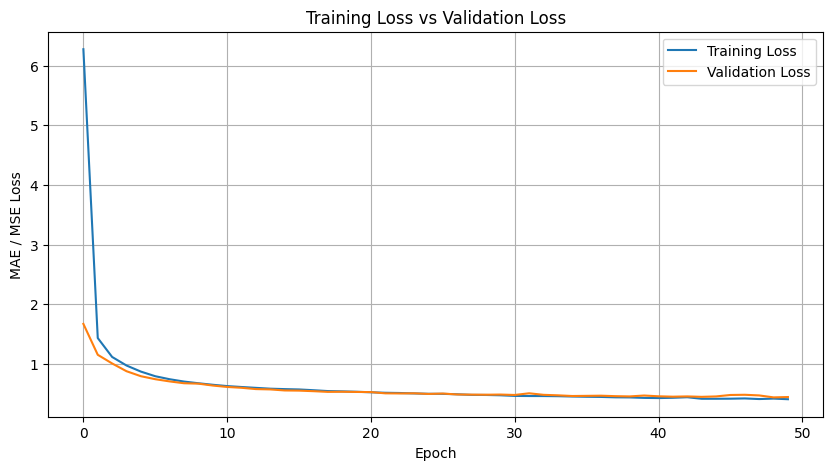

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['mae'], label='Training Loss')
plt.plot(history.history['val_mae'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

In [ ]:
def build_model(params, input_dim):

    model = models.Sequential()

    model.add(layers.Input(shape=(input_dim,)))

    for i in range(params['n_layers']):

        model.add(layers.Dense(
            params[f'units_{i}'],
            activation=params['activation'],
            kernel_initializer='he_normal' if params['activation'] == 'relu' else 'glorot_uniform',
            kernel_regularizer=regularizers.l2(params['l2'])
        ))

        if params['dropout'] > 0:
            model.add(layers.Dropout(params['dropout']))

    model.add(layers.Dense(1, activation='linear'))

    if params['optimizer'] == 'adam':
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=params['learning_rate']
        )
    else:
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=params['learning_rate']
        )

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [ ]:
def objective(trial):

    params = {
        'n_layers': trial.suggest_int('n_layers', 1, 4),

        'activation': trial.suggest_categorical(
            'activation', ['relu', 'tanh']
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate', 1e-5, 1e-2, log=True
        ),

        'dropout': trial.suggest_float(
            'dropout', 0.0, 0.5
        ),

        'l2': trial.suggest_float(
            'l2', 1e-7, 1e-2, log=True
        ),

        'optimizer': trial.suggest_categorical(
            'optimizer', ['adam', 'rmsprop']
        )
    }

    # Tune neurons in each hidden layer
    for i in range(params['n_layers']):
        params[f'units_{i}'] = trial.suggest_categorical(
            f'units_{i}', [16, 32, 64, 128, 256]
        )

    batch_size = trial.suggest_categorical(
        'batch_size', [16, 32, 64, 128]
    )

    # Create a fresh model for every trial
    tf.keras.backend.clear_session()

    model = build_model(
        params,
        input_dim=x_train.shape[1]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    model.fit(
        x_train,
        y_train,
        epochs=150,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
        callbacks=[early_stop],
        verbose=0
    )

    y_pred = model.predict(x_val, verbose=0).flatten()

    score = r2_score(y_val, y_pred)

    return score

In [ ]:
study = optuna.create_study(
    direction='maximize'
)

study.optimize(
    objective,
    n_trials=50
)

[I 2026-11-01 10:52:06,382] A new study created in memory with name: no-name-f99564e5-9aa1-4394-84ef-e6b57f7fc10d
[I 2026-11-01 10:52:25,681] Trial 0 finished with value: 0.47784726523987164 and parameters: {'n_layers': 2, 'activation': 'relu', 'learning_rate': 0.004117074901933199, 'dropout': 0.15568080885801844, 'l2': 2.953821670762449e-06, 'optimizer': 'adam', 'units_0': 128, 'units_1': 64, 'batch_size': 64}. Best is trial 0 with value: 0.47784726523987164.
[I 2026-11-01 10:53:39,458] Trial 1 finished with value: -0.047232420102462536 and parameters: {'n_layers': 2, 'activation': 'relu', 'learning_rate': 9.25241249871437e-05, 'dropout': 0.4743661655001247, 'l2': 0.00020798138836952134, 'optimizer': 'adam', 'units_0': 128, 'units_1': 64, 'batch_size': 16}. Best is trial 0 with value: 0.47784726523987164.
[I 2026-11-01 10:53:58,043] Trial 2 finished with value: -26.7077125341467 and parameters: {'n_layers': 3, 'activation': 'relu', 'learning_rate': 3.870389124978455e-05, 'dropout': 0.

In [ ]:
print("Best R2 Score:", study.best_value)
print("Best Parameters:", study.best_params)

Best R2 Score: 0.5260398006104541
Best Parameters: {'n_layers': 4, 'activation': 'relu', 'learning_rate': 0.008810623663603271, 'dropout': 0.14694112078378974, 'l2': 6.735709099199742e-07, 'optimizer': 'rmsprop', 'units_0': 32, 'units_1': 32, 'units_2': 256, 'units_3': 16, 'batch_size': 16}


In [ ]:
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal', input_shape=(x_train.shape[1],)))
model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(16, activation='relu', kernel_initializer='he_normal'))
model.add(layers.Dense(1, activation='linear'))

In [ ]:
model = models.Sequential()

model.add(layers.Input(shape=(x_train.shape[1],)))

model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(6.735709099199742e-07)))
model.add(layers.Dropout(0.14694112078378974))
model.add(layers.Dense(32, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(6.735709099199742e-07)))
model.add(layers.Dropout(0.14694112078378974))
model.add(layers.Dense(256, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(6.735709099199742e-07)))
model.add(layers.Dropout(0.14694112078378974))
model.add(layers.Dense(16, activation='relu', kernel_initializer='he_normal', kernel_regularizer=regularizers.l2(6.735709099199742e-07)))
model.add(layers.Dropout(0.14694112078378974))
model.add(layers.Dense(1, activation='linear'))

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.008810623663603271),
    loss='mse',
    metrics=['mae']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=150,
    batch_size=16,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - loss: 12.6142 - mae: 2.6358 - val_loss: 4.8927 - val_mae: 2.0146
Epoch 2/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 5.7432 - mae: 1.9027 - val_loss: 0.7914 - val_mae: 0.7112
Epoch 3/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.9924 - mae: 1.5682 - val_loss: 0.8645 - val_mae: 0.7533
Epoch 4/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.2252 - mae: 1.4165 - val_loss: 0.7404 - val_mae: 0.7147
Epoch 5/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.9550 - mae: 1.3526 - val_loss: 0.4688 - val_mae: 0.5202
Epoch 6/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.9726 - mae: 1.3677 - val_loss: 0.5681 - val_mae: 0.6142
Epoch 7/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4584 - mae: 1.2391 - val_loss: 0.4277 - val_mae: 0.5029
Epoch 8/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.4381 - mae: 1.2330 - val_loss: 0.7019 - val_mae: 0.6711
Epoch 9/150
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3

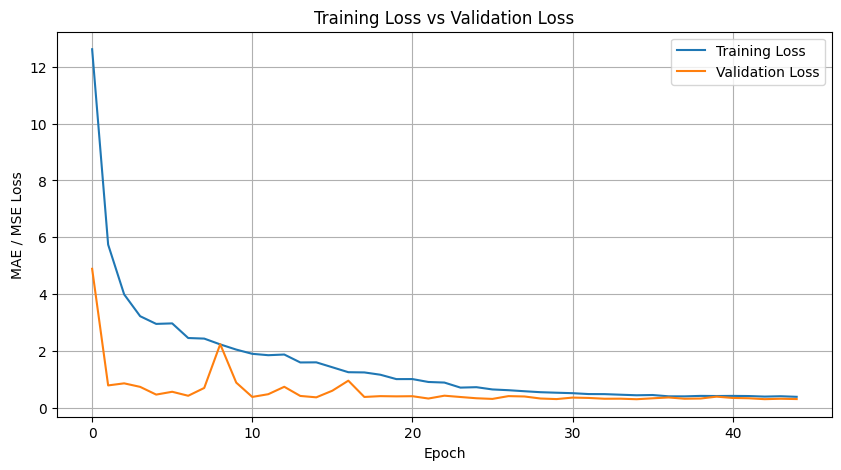

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

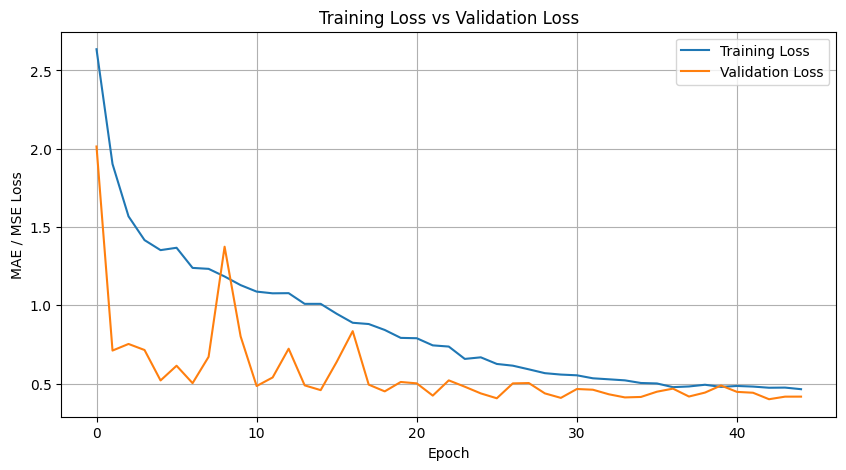

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['mae'], label='Training Loss')
plt.plot(history.history['val_mae'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step
MAE 13171.481818181815
R2_Score 0.3204135142746648


Without exp (Log Scale)
MAE: 0.46270022542582995
R2_Score: 0.45639526139297504


In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [ ]:
import keras_tuner as kt

In [ ]:
def build_model(hp):

    model = models.Sequential()

    model.add(layers.Input(shape=(x_train.shape[1],)))

    # Tune number of hidden layers
    n_layers = hp.Int(
        'n_layers',
        min_value=1,
        max_value=4,
        step=1
    )

    for i in range(n_layers):

        # Tune number of neurons
        units = hp.Choice(
            f'units_{i}',
            values=[16, 32, 64, 128, 256]
        )

        # Tune activation function
        activation = hp.Choice(
            'activation',
            values=['relu', 'tanh']
        )

        # Tune L2 regularization
        l2_value = hp.Float(
            'l2',
            min_value=1e-7,
            max_value=1e-2,
            sampling='log'
        )

        model.add(
            layers.Dense(
                units=units,
                activation=activation,
                kernel_initializer='he_normal',
                kernel_regularizer=regularizers.l2(l2_value)
            )
        )

        # Tune dropout
        dropout_rate = hp.Float(
            'dropout',
            min_value=0.0,
            max_value=0.5,
            step=0.1
        )

        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(1, activation='linear'))

    # Tune optimizer
    optimizer_name = hp.Choice(
        'optimizer',
        values=['adam', 'rmsprop']
    )

    # Tune learning rate
    learning_rate = hp.Float(
        'learning_rate',
        min_value=1e-5,
        max_value=1e-2,
        sampling='log'
    )

    if optimizer_name == 'adam':
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [ ]:
tuner = kt.BayesianOptimization(
    hypermodel=build_model,
    objective='val_loss',
    max_trials=50,
    num_initial_points=10,
    directory='keras_tuning',
    project_name='laptop_price'
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

tuner.search(
    x_train,
    y_train,
    epochs=100,
    validation_data=(x_val, y_val),
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Trial 50 Complete [00h 00m 16s]
val_loss: 0.41724735498428345

Best val_loss So Far: 0.2997748553752899
Total elapsed time: 00h 22m 48s


In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print(best_hp.values)

{'n_layers': 1, 'units_0': 256, 'activation': 'tanh', 'l2': 1.7985305462078237e-07, 'dropout': 0.30000000000000004, 'optimizer': 'adam', 'learning_rate': 0.01, 'units_1': 256, 'units_2': 256, 'units_3': 256}


In [ ]:
model = models.Sequential()

model.add(layers.Input(shape=(x_train.shape[1],)))

model.add(layers.Dense(256, activation='tanh', kernel_initializer='glorot_normal', kernel_regularizer=regularizers.l2(1.7985305462078237e-07)))
model.add(layers.Dropout(0.30000000000000004))
model.add(layers.Dense(1, activation='linear'))

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='mse',
    metrics=['mae']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - loss: 9.8209 - mae: 2.1688 - val_loss: 1.0000 - val_mae: 0.7909
Epoch 2/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1616 - mae: 0.8450 - val_loss: 0.6414 - val_mae: 0.5935
Epoch 3/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0350 - mae: 0.8017 - val_loss: 0.6805 - val_mae: 0.6306
Epoch 4/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9270 - mae: 0.7612 - val_loss: 0.5714 - val_mae: 0.5673
Epoch 5/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9413 - mae: 0.7671 - val_loss: 0.5301 - val_mae: 0.5356
Epoch 6/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8628 - mae: 0.7265 - val_loss: 0.5322 - val_mae: 0.5523
Epoch 7/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8266 - mae: 0.7158 - val_loss: 0.4724 - val_mae: 0.4984
Epoch 8/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7950 - mae: 0.6954 - val_loss: 0.4193 - val_mae: 0.4742
Epoch 9/150
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.80

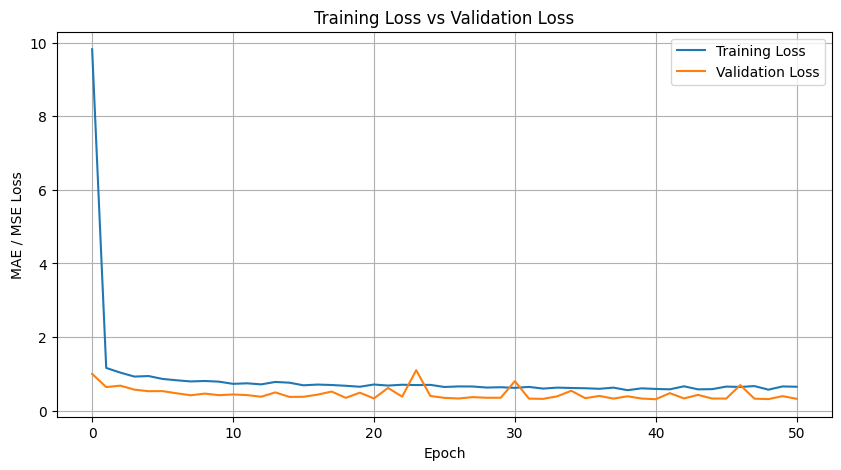

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

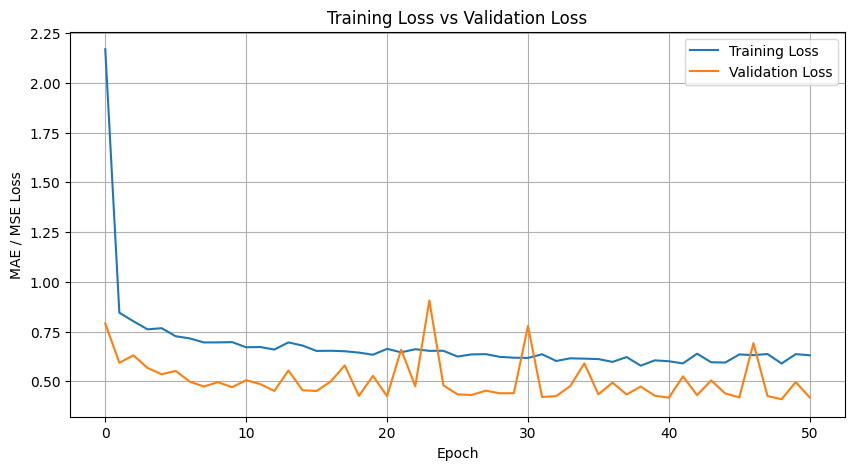

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['mae'], label='Training Loss')
plt.plot(history.history['val_mae'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MAE / MSE Loss')
plt.title('Training Loss vs Validation Loss')

plt.legend()
plt.grid()
plt.show()

In [ ]:
y_pred = model.predict(x_test).flatten()
y_test_original = np.exp(y_test)
y_pred_original = np.exp(y_pred)

print("MAE", mean_absolute_error(y_test_original, y_pred_original))
print('R2_Score', r2_score( y_test_original, y_pred_original))


print("\n" + "=" * 40 + "\n")

print("Without exp (Log Scale)")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2_Score:", r2_score(y_test, y_pred))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
MAE 12574.425117631392
R2_Score 0.46018312317878274


Without exp (Log Scale)
MAE: 0.47538223828415493
R2_Score: 0.3967895889186681


In [12]:
model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    verbose=0,
    random_seed=42,
    cat_features=categorical_col
)

In [13]:
model.fit(
    x,
    y,
    cat_features=categorical_col
)

CatBoostRegressor(cat_features=['Brand', 'Storage_Type', 'Processor'], depth=8, iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=0)

In [19]:
dist = pd.DataFrame({
    'Brand': ['dell'],
    'RAM_GB': [3.0],
    'ROM_GB': [256],
    'Screen_Size': [14.0],
    'Storage_Type': ['Unspecified'],
    'Processor': ['Intel Core i5'],
    'Warranty_Days': [0.0],
    'Screen_Size_missing': [1],
    'Processor_Tier_missing': [0],
    'Is_Laptop': [1]
})

In [20]:
y_pred = model.predict(dist)

y_pred

array([9.8504749])

In [14]:
x.head(2)

,Brand,RAM_GB,ROM_GB,Screen_Size,Storage_Type,Processor,Warranty_Days,Screen_Size_missing,Processor_Tier_missing,Is_Laptop
0,macbook,4.0,256,24.0,SSD,Apple M1,0.0,0,1,0
1,dell,3.0,256,14.0,Unspecified,Intel Core i5,0.0,1,0,1


In [17]:
y.head(2)

,Price
0,11.082143
1,10.126591
